In [4]:
!pip install -q pgmpy

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

In [6]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'target'
]

data = pd.read_csv(
    url,
    names=columns,
    na_values='?'
)

print("First five records:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

First five records:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Dataset Shape:
(303, 14)


In [7]:
# Remove missing values
data = data.dropna().copy()

# Convert target into binary classification
data['target'] = (data['target'] > 0).astype(int)

# Convert continuous attributes into categories
data['age'] = pd.cut(
    data['age'],
    bins=[0, 40, 50, 60, 100],
    labels=False
)

data['thalach'] = pd.cut(
    data['thalach'],
    bins=[0, 100, 140, 170, 250],
    labels=False
)

data['oldpeak'] = pd.cut(
    data['oldpeak'],
    bins=[-1, 1, 2, 4, 10],
    labels=False
)

data['chol'] = pd.cut(
    data['chol'],
    bins=[0, 200, 240, 300, 600],
    labels=False
)

# Select important attributes
features = [
    'age', 'sex', 'cp', 'chol',
    'thalach', 'exang', 'oldpeak',
    'ca', 'thal'
]

data = data[features + ['target']].copy()

# Convert values into integers
data = data.astype(int)

print("Preprocessed Dataset:")
print(data.head())

print("\nDataset Shape After Cleaning:")
print(data.shape)

Preprocessed Dataset:
   age  sex  cp  chol  thalach  exang  oldpeak  ca  thal  target
0    3    1   1     1        2      0        2   0     6       0
1    3    1   4     2        1      1        1   3     3       1
2    3    1   4     1        1      1        2   2     7       1
3    0    1   3     2        3      0        2   0     3       0
4    1    0   2     1        3      0        1   0     3       0

Dataset Shape After Cleaning:
(297, 10)


In [8]:
model = DiscreteBayesianNetwork([
    ('target', 'age'),
    ('target', 'sex'),
    ('target', 'cp'),
    ('target', 'chol'),
    ('target', 'thalach'),
    ('target', 'exang'),
    ('target', 'oldpeak'),
    ('target', 'ca'),
    ('target', 'thal')
])

print("Bayesian Network Structure:")
print(model.edges())

Bayesian Network Structure:
[('target', 'age'), ('target', 'sex'), ('target', 'cp'), ('target', 'chol'), ('target', 'thalach'), ('target', 'exang'), ('target', 'oldpeak'), ('target', 'ca'), ('target', 'thal')]


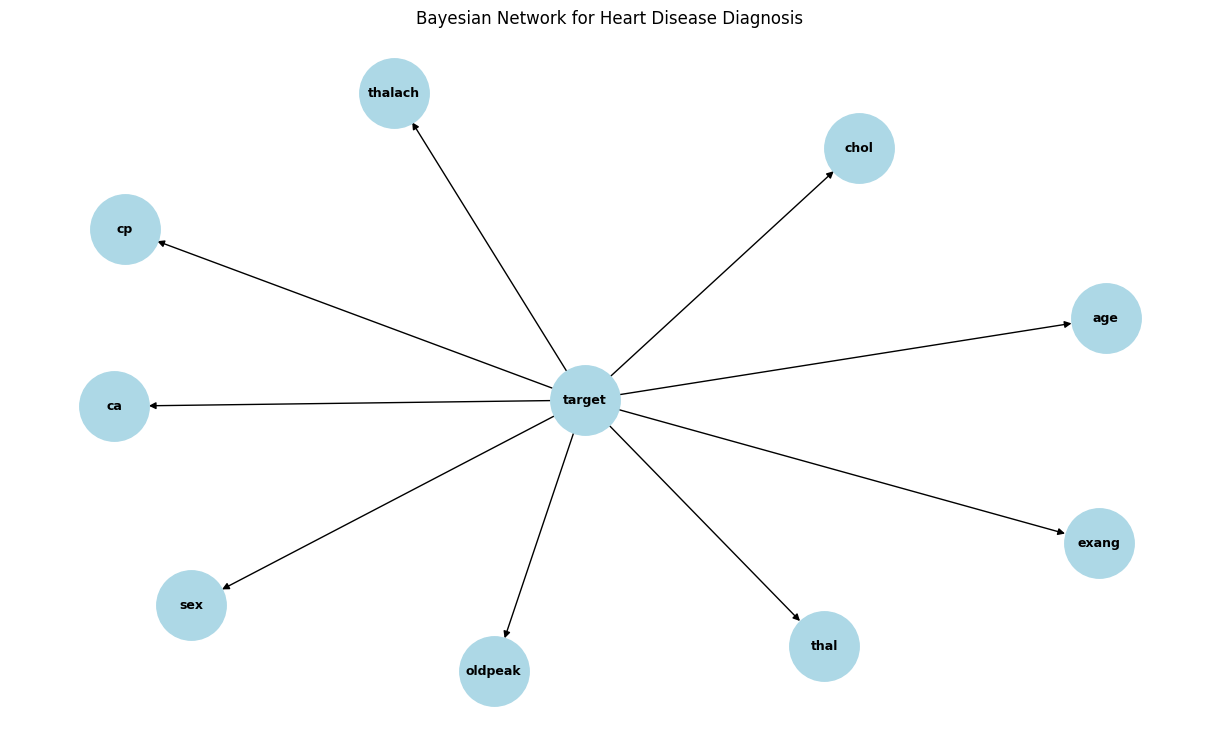

In [9]:
G = nx.DiGraph()

G.add_edges_from(model.edges())

plt.figure(figsize=(12, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    node_color='lightblue',
    font_size=9,
    font_weight='bold',
    arrows=True
)

plt.title("Bayesian Network for Heart Disease Diagnosis")

plt.show()

In [15]:
# Train using Bayesian Estimator

estimator = BayesianEstimator(
    model,
    data
)

cpds = estimator.get_parameters(
    prior_type='BDeu',
    equivalent_sample_size=10
)

model.add_cpds(*cpds)

print("Bayesian Network trained successfully!")

Bayesian Network trained successfully!


C:\Users\jsami\AppData\Local\Temp\ipykernel_4392\456076192.py:3: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(


In [17]:
for cpd in model.get_cpds():
    print(cpd)
    print("-------------------------")

+-----------+----------+
| target(0) | 0.537459 |
+-----------+----------+
| target(1) | 0.462541 |
+-----------+----------+
-------------------------
+--------+---------------------+----------------------+
| target | target(0)           | target(1)            |
+--------+---------------------+----------------------+
| age(0) | 0.07424242424242425 | 0.051056338028169015 |
+--------+---------------------+----------------------+
| age(1) | 0.3287878787878788  | 0.1637323943661972   |
+--------+---------------------+----------------------+
| age(2) | 0.37727272727272726 | 0.4665492957746479   |
+--------+---------------------+----------------------+
| age(3) | 0.2196969696969697  | 0.31866197183098594  |
+--------+---------------------+----------------------+
-------------------------
+--------+---------------------+--------------------+
| target | target(0)           | target(1)          |
+--------+---------------------+--------------------+
| sex(0) | 0.44545454545454544 | 0.1936619718

In [18]:
inference = VariableElimination(model)

# Example patient medical information
patient = {
    'age': 2,
    'sex': 1,
    'cp': 4,
    'chol': 2,
    'thalach': 1,
    'exang': 1,
    'oldpeak': 2,
    'ca': 1,
    'thal': 3
}

result = inference.query(
    variables=['target'],
    evidence=patient
)

print("Heart Disease Probability:")
print(result)

Heart Disease Probability:
+-----------+---------------+
| target    |   phi(target) |
+===========+===============+
| target(0) |        0.0031 |
+-----------+---------------+
| target(1) |        0.9969 |
+-----------+---------------+


In [19]:
probabilities = result.values

no_disease = probabilities[0] * 100
disease = probabilities[1] * 100

print("Heart Disease Diagnosis")
print("-----------------------")

print(f"No Heart Disease: {no_disease:.2f}%")
print(f"Heart Disease: {disease:.2f}%")

if disease > no_disease:
    print("\nModel Prediction: Heart Disease Present")
else:
    print("\nModel Prediction: No Heart Disease")

Heart Disease Diagnosis
-----------------------
No Heart Disease: 0.31%
Heart Disease: 99.69%

Model Prediction: Heart Disease Present
